In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import nltk
import re

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import PorterStemmer, LancasterStemmer, SnowballStemmer
from nltk.corpus import stopwords

nltk.download('stopwords')

import os
dataset_path = r'D:\movie-recommendation-system\dataset\Rotten Tomatoes Movies 2.csv'

if os.path.exists(dataset_path):
    df = pd.read_csv(dataset_path)
    print("File imported successfully")
else:
    print("File does not exist")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


File imported successfully


In [201]:
df.head()

,movie_title,movie_info,critics_consensus,rating,genre,directors,writers,cast,in_theaters_date,on_streaming_date,runtime_in_minutes,studio_name,tomatometer_status,tomatometer_rating,tomatometer_count,audience_rating,audience_count
0,Percy Jackson & the Olympians: The Lightning T...,A teenager discovers he's the descendant of a ...,Though it may seem like just another Harry Pot...,PG,"Action & Adventure, Comedy, Drama, Science Fic...",Chris Columbus,Craig Titley,"Logan Lerman, Brandon T. Jackson, Alexandra Da...",2010-02-12,2010-06-29,83.0,20th Century Fox,Rotten,49,144,53.0,254287.0
1,Please Give,Kate has a lot on her mind. There's the ethics...,Nicole Holofcener's newest might seem slight i...,R,Comedy,Nicole Holofcener,Nicole Holofcener,"Catherine Keener, Amanda Peet, Oliver Platt, R...",2010-04-30,2010-10-19,90.0,Sony Pictures Classics,Certified Fresh,86,140,64.0,11567.0
2,10,Blake Edwards' 10 stars Dudley Moore as George...,NaN,R,"Comedy, Romance",Blake Edwards,Blake Edwards,"Dudley Moore, Bo Derek, Julie Andrews, Robert ...",1979-10-05,1997-08-27,118.0,Waner Bros.,Fresh,68,22,53.0,14670.0
3,12 Angry Men (Twelve Angry Men),"A Puerto Rican youth is on trial for murder, a...",Sidney Lumet's feature debut is a superbly wri...,NR,"Classics, Drama",Sidney Lumet,Reginald Rose,"Martin Balsam, John Fiedler, Lee J. Cobb, E.G....",1957-04-13,2001-03-06,95.0,Criterion Collection,Certified Fresh,100,51,97.0,105000.0
4,"20,000 Leagues Under The Sea","This 1954 Disney version of Jules Verne's 20,0...","One of Disney's finest live-action adventures,...",G,"Action & Adventure, Drama, Kids & Family",Richard Fleischer,Earl Felton,"James Mason, Kirk Douglas, Paul Lukas, Peter L...",1954-01-01,2003-05-20,127.0,Disney,Fresh,89,27,74.0,68860.0


In [202]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16638 entries, 0 to 16637
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   movie_title         16638 non-null  str    
 1   movie_info          16614 non-null  str    
 2   critics_consensus   8309 non-null   str    
 3   rating              16638 non-null  str    
 4   genre               16621 non-null  str    
 5   directors           16524 non-null  str    
 6   writers             15289 non-null  str    
 7   cast                16354 non-null  str    
 8   in_theaters_date    15823 non-null  str    
 9   on_streaming_date   16636 non-null  str    
 10  runtime_in_minutes  16483 non-null  float64
 11  studio_name         16222 non-null  str    
 12  tomatometer_status  16638 non-null  str    
 13  tomatometer_rating  16638 non-null  int64  
 14  tomatometer_count   16638 non-null  int64  
 15  audience_rating     16386 non-null  float64
 16  audience_count 

In [203]:
df.describe()

,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
count,16483.000000,16638.000000,16638.000000,16386.000000,1.638600e+04
mean,102.391494,60.466522,56.607104,60.470829,1.524797e+05
std,25.028011,28.587230,66.383800,20.462368,1.817736e+06
min,1.000000,0.000000,5.000000,0.000000,5.000000e+00
25%,90.000000,38.000000,12.000000,45.000000,8.642500e+02
50%,99.000000,66.000000,28.000000,62.000000,4.876500e+03
75%,111.000000,86.000000,76.000000,77.000000,2.875200e+04
max,2000.000000,100.000000,497.000000,100.000000,3.579764e+07


<Axes: xlabel='runtime_in_minutes'>

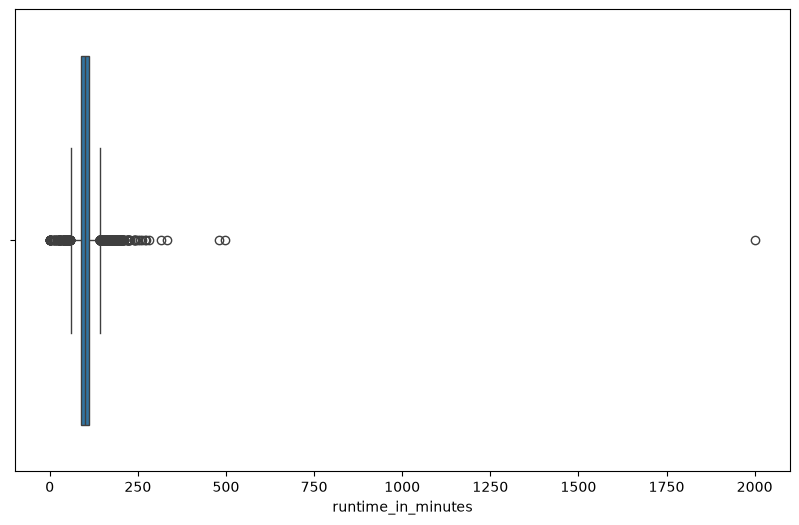

In [204]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='runtime_in_minutes', data=df)

In [205]:
df= df[df['runtime_in_minutes'] < 400]

<Axes: xlabel='audience_count'>

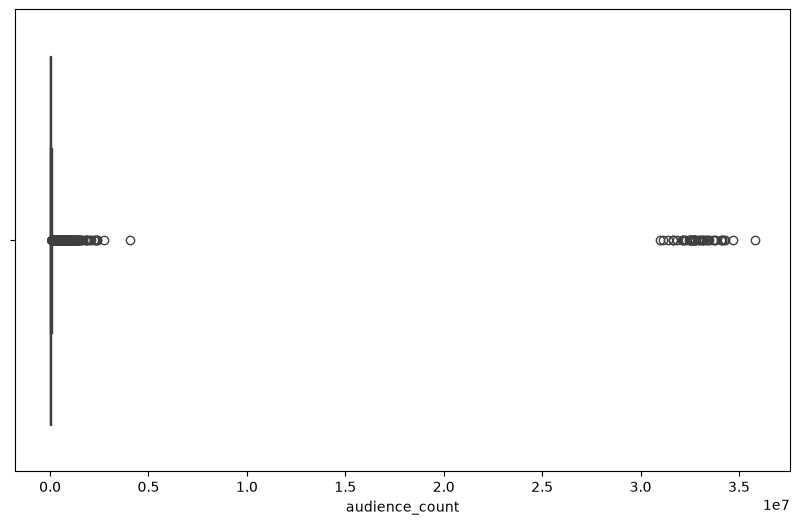

In [206]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='audience_count', data=df)

<Axes: xlabel='tomatometer_count'>

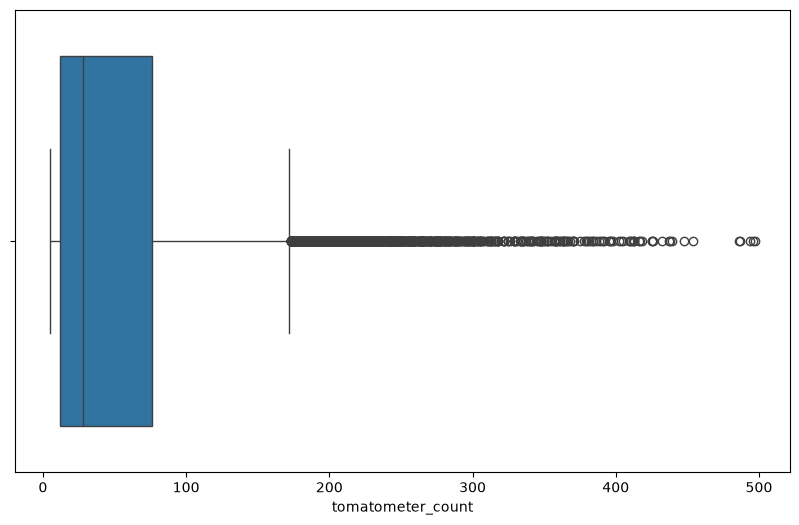

In [207]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='tomatometer_count', data=df)

In [208]:
#df=df[df['tomatometer_count'] < 400]

In [209]:
df["tomatometer_status"].value_counts()

tomatometer_status
Rotten             7134
Fresh              6404
Certified Fresh    2942
Name: count, dtype: int64

In [210]:
df['theater_age']=df['in_theaters_date'].str.split('-').str[0].astype(float)
df['theater_age']=2019-df['theater_age']

df['streaming_age']=df['on_streaming_date'].str.split('-').str[0].astype(float)
df['streaming_age']=2019-df['streaming_age']

df[['streaming_age','theater_age']].describe()
#age me change kar sakta hu months ka use kar sakta hu abhi ke liye sahi hai

,streaming_age,theater_age
count,16478.000000,15695.000000
mean,10.965408,19.821854
std,6.462070,19.397287
min,0.000000,0.000000
25%,5.000000,6.000000
50%,11.000000,13.000000
75%,16.000000,26.000000
max,84.000000,105.000000


<Axes: xlabel='streaming_age', ylabel='count'>

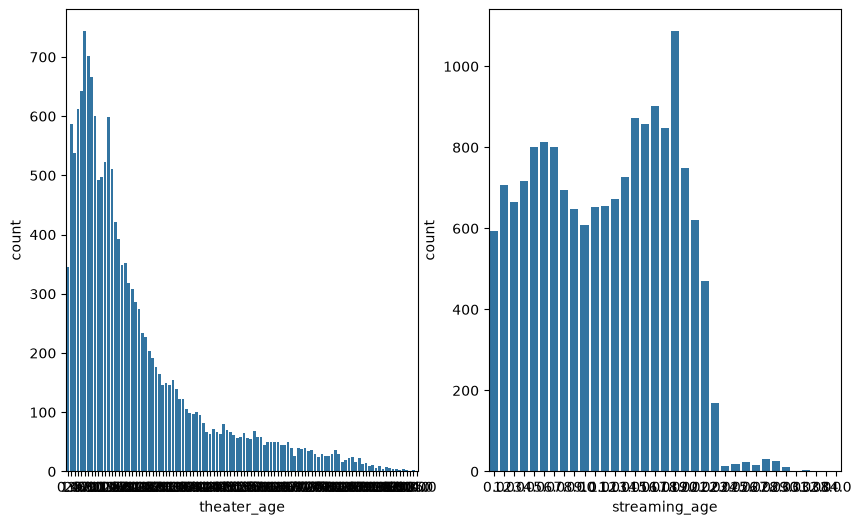

In [211]:
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
sns.countplot(x='theater_age', data=df)
plt.subplot(1, 2, 2)
sns.countplot(x='streaming_age', data=df)

In [212]:
df['streaming_age'].value_counts().tail(30)

streaming_age
5.0     814
4.0     801
6.0     801
19.0    748
13.0    728
3.0     716
1.0     708
7.0     695
12.0    672
2.0     664
11.0    656
10.0    652
8.0     648
20.0    621
9.0     608
0.0     593
21.0    471
22.0    170
27.0     31
28.0     26
25.0     24
24.0     19
26.0     15
23.0     13
29.0     11
31.0      3
84.0      1
30.0      1
33.0      1
32.0      1
Name: count, dtype: int64

#age ke data ke liye np.log1p use karna hoga

#months age me use nhi kiya

#streaming age me lower count data delete nhi kiya

In [213]:
df.head(1)

,movie_title,movie_info,critics_consensus,rating,genre,directors,writers,cast,in_theaters_date,on_streaming_date,runtime_in_minutes,studio_name,tomatometer_status,tomatometer_rating,tomatometer_count,audience_rating,audience_count,theater_age,streaming_age
0,Percy Jackson & the Olympians: The Lightning T...,A teenager discovers he's the descendant of a ...,Though it may seem like just another Harry Pot...,PG,"Action & Adventure, Comedy, Drama, Science Fic...",Chris Columbus,Craig Titley,"Logan Lerman, Brandon T. Jackson, Alexandra Da...",2010-02-12,2010-06-29,83.0,20th Century Fox,Rotten,49,144,53.0,254287.0,9.0,9.0


In [214]:
df.columns

Index(['movie_title', 'movie_info', 'critics_consensus', 'rating', 'genre',
       'directors', 'writers', 'cast', 'in_theaters_date', 'on_streaming_date',
       'runtime_in_minutes', 'studio_name', 'tomatometer_status',
       'tomatometer_rating', 'tomatometer_count', 'audience_rating',
       'audience_count', 'theater_age', 'streaming_age'],
      dtype='str')

In [215]:
df["studio_name"].value_counts()

studio_name
Paramount Pictures              493
Warner Bros. Pictures           483
Universal Pictures              465
20th Century Fox                408
IFC Films                       396
                               ... 
Jigsaw Productions                1
The Jerry Gross Organization      1
Triumph Films                     1
Typecast Pictures                 1
Tango Entertainment               1
Name: count, Length: 2871, dtype: int64

In [216]:
df['writers'].value_counts()

writers
Woody Allen                                                    33
Neil Simon                                                     19
Werner Herzog                                                  19
Ingmar Bergman                                                 18
David Mamet                                                    18
                                                               ..
Justin Theroux, Ben Stiller, Nicholas Stoller, John Hamburg     1
Adam Rifkin, David Berenbaum                                    1
Jared Bush, Phil Johnston                                       1
Cy Endfield, John Prebble                                       1
Cy Endfield, Anthony Storey                                     1
Name: count, Length: 12019, dtype: int64

In [217]:
df['rating'].value_counts()

rating
R         6092
NR        4792
PG-13     2847
PG        2056
G          652
NC17        37
PG-13)       3
R)           1
Name: count, dtype: int64

In [218]:
df['rating']=df['rating'].apply(lambda x : 'dirty' if x in ['R)', 'PG-13)'] else x )
df['rating'].value_counts()

rating
R        6092
NR       4792
PG-13    2847
PG       2056
G         652
NC17       37
dirty       4
Name: count, dtype: int64

In [219]:
df.isnull().sum()

movie_title              0
movie_info              20
critics_consensus     8268
rating                   0
genre                   17
directors              110
writers               1337
cast                   282
in_theaters_date       785
on_streaming_date        2
runtime_in_minutes       0
studio_name            410
tomatometer_status       0
tomatometer_rating       0
tomatometer_count        0
audience_rating        244
audience_count         244
theater_age            785
streaming_age            2
dtype: int64

In [220]:
df['movie_title'] = df['movie_title'].drop_duplicates()

In [221]:
df = df.dropna(subset=['streaming_age']).reset_index(drop=True)
df['theater_age'] = df['theater_age'].fillna(df['streaming_age'])

In [222]:
df['audience_rating'] = df['audience_rating'].fillna(df['audience_rating'].median())
df['audience_count'] = df['audience_count'].fillna(df['audience_count'].median())

In [223]:
df.isnull().sum()

movie_title            520
movie_info              20
critics_consensus     8266
rating                   0
genre                   17
directors              110
writers               1335
cast                   282
in_theaters_date       783
on_streaming_date        0
runtime_in_minutes       0
studio_name            408
tomatometer_status       0
tomatometer_rating       0
tomatometer_count        0
audience_rating          0
audience_count           0
theater_age              0
streaming_age            0
dtype: int64

#text cleaning 

In [224]:
ps = PorterStemmer()
stop = set(stopwords.words('english'))

# NaN value handling
for c in ['genre', 'directors', 'cast', 'movie_info', 'critics_consensus', 'studio_name', 'writers']:
    df[c] = df[c].fillna('')

# names and genres: split by comma, spaces hata rha 
def collapse(text):
    return [i.replace(' ', '').replace('&', '').lower() for i in text.split(',') if i.strip()]

df['genre_l'] = df['genre'].apply(collapse)
df['directors_l'] = df['directors'].apply(collapse)
df['cast_l'] = df['cast'].apply(collapse)
df['studio_name_l'] = df['studio_name'].apply(collapse)
df['writers_l'] = df['writers'].apply(collapse)

# description: clean + stemming 
def clean_text(text):
    words = re.sub(r'[^a-zA-Z\s]', '', text.lower()).split()
    return [ps.stem(w) for w in words if w not in stop]

df['info_l'] = (df['movie_info'] + ' ' + df['critics_consensus']).apply(clean_text)

df['status_l'] = df['tomatometer_status'].apply(lambda x: [x.replace(' ', '').lower()])

df['tags'] = (df['genre_l'] + df['directors_l'] + df['cast_l'] + df['info_l'] + df['studio_name_l'] + df['writers_l'] + df['status_l']).apply(lambda x: ' '.join(x))

**Similarity vector bana rha**

In [225]:
df.columns

Index(['movie_title', 'movie_info', 'critics_consensus', 'rating', 'genre',
       'directors', 'writers', 'cast', 'in_theaters_date', 'on_streaming_date',
       'runtime_in_minutes', 'studio_name', 'tomatometer_status',
       'tomatometer_rating', 'tomatometer_count', 'audience_rating',
       'audience_count', 'theater_age', 'streaming_age', 'genre_l',
       'directors_l', 'cast_l', 'studio_name_l', 'writers_l', 'info_l',
       'status_l', 'tags'],
      dtype='str')

In [ ]:

#used ai here for handling num values with txt
# 1. numeric columns
num_cols = ['runtime_in_minutes', 'tomatometer_rating', 'tomatometer_count','audience_rating', 'audience_count', 'theater_age', 'streaming_age']

num = df[num_cols].copy()
for c in ['audience_count', 'tomatometer_count', 'theater_age', 'streaming_age']:
    num[c] = np.log1p(num[c]) #handling skew value jyada skew hai isiliye log1p use kiya

num_scaled = MinMaxScaler().fit_transform(num)

# 2. TF-IDF
tfidf = TfidfVectorizer(max_features=10000)
tfidf_vec = tfidf.fit_transform(df['tags'])

# 3. merge (numeric weight kam)
w = 0.2
final_vec = hstack([tfidf_vec, csr_matrix(num_scaled * w)]).tocsr()

# 4. similarity
similarity = cosine_similarity(final_vec).astype('float32')

# 5. re-ranking score (similarity se alag, 0-1 scaled)
rank_cols = ['audience_rating', 'tomatometer_rating', 'audience_count']
rank = MinMaxScaler().fit_transform(
    df[rank_cols].assign(audience_count=np.log1p(df['audience_count']))
)
df['quality'] = rank.mean(axis=1)

In [ ]:
def recommend(title, n=10, alpha=0.8):
    matches = df[df['movie_title'].str.lower() == title.lower()]
    if matches.empty:
        return "Movie not found"
    idx = matches.index[0]

    sim = similarity[idx]
    final_score = alpha * sim + (1 - alpha) * df['quality'].values

    top = np.argsort(final_score)[::-1]
    top = [i for i in top if i != idx][:n]

    return df.loc[top, ['movie_title', 'genre', 'audience_rating']].assign(score=final_score[top])

In [234]:
recommend('12 Angry men')

,movie_title,genre,audience_rating,score
3,12 Angry Men (Twelve Angry Men),"Classics, Drama",97.0,0.367598
10539,Ocean's Eleven,"Action & Adventure, Comedy, Drama",80.0,0.322648
2611,Anatomy of a Murder,"Classics, Drama, Mystery & Suspense",90.0,0.318016
12053,Save the Tiger,"Classics, Drama",74.0,0.301761
702,Shadow of a Doubt,"Classics, Drama, Mystery & Suspense",90.0,0.301287
12368,The Shining,"Drama, Horror, Mystery & Suspense, Special Int...",93.0,0.301135
2980,Bagdad Cafe,"Art House & International, Comedy, Drama",88.0,0.301078
12663,Some Like It Hot,"Classics, Comedy, Drama, Musical & Performing ...",94.0,0.300218
14,Adam's Rib,"Classics, Comedy, Romance",86.0,0.298909
11930,Runaway Jury,"Drama, Mystery & Suspense",75.0,0.298441
